<a href="https://colab.research.google.com/github/nara-yama/osurankreg/blob/main/selfcomparisontoolosu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [153]:
from google.colab import userdata

client_id = int(userdata.get("OSU_CLIENT_ID"))
client_secret = userdata.get("OSU_CLIENT_SECRET")

token_res = requests.post("https://osu.ppy.sh/oauth/token", data={
    "client_id": client_id,
    "client_secret": client_secret,
    "grant_type": "client_credentials",
    "scope": "public"
})
token = token_res.json()["access_token"]
H = {"Authorization": f"Bearer {token}"}

#Global use (all digit dataset)

In [ ]:
import requests, time
import pandas as pd
import matplotlib.pyplot as plt

START, END = 1, 200
total = END - START + 1
rows = []

def progress(done, total, width=30):
    filled = int(width * done / total)
    bar = "█" * filled + "-" * (width - filled)
    print(f"\r[{bar}] {done}/{total} pages ({done/total:.0%}) | {len(rows)} players", end="", flush=True)

progress(0, total)
for i, page in enumerate(range(START, END + 1), start=1):
    url = "https://osu.ppy.sh/api/v2/rankings/osu/performance"
    params = {"country": "ID", "cursor[page]": page}
    r = requests.get(url, headers=H, params=params)
    if r.status_code == 429:
        time.sleep(10)
        r = requests.get(url, headers=H, params=params)
    r.raise_for_status()
    for s in r.json()["ranking"]:
        rows.append({
            "user_id": s["user"]["id"],
            "username": s["user"]["username"],
            "global_rank": s.get("global_rank"),
            "pp": s["pp"],
            "hours": s["play_time"] / 3600,
        })
    progress(i, total)
    time.sleep(1.1)
print("\nDone!")

[██████████████████████████████] 200/200 pages (100%) | 10000 players
Done!


In [ ]:
rows_g = []
for page in range(1, 11):
    url = "https://osu.ppy.sh/api/v2/rankings/osu/performance"
    params = {"cursor[page]": page}          # no country filter
    r = requests.get(url, headers=H, params=params)
    if r.status_code == 429:
        time.sleep(10)
        r = requests.get(url, headers=H, params=params)
    r.raise_for_status()
    for s in r.json()["ranking"]:
        rows_g.append({
            "user_id": s["user"]["id"],
            "username": s["user"]["username"],
            "global_rank": s.get("global_rank"),
            "pp": s["pp"],
            "hours": s["play_time"] / 3600,
        })
    print(f"\r{page}/10", end="", flush=True)
    time.sleep(1.1)

df_g = pd.DataFrame(rows_g).dropna(subset=["global_rank"])
df_all = pd.concat([df, df_g]).drop_duplicates("user_id").reset_index(drop=True)
print(f"\n{len(df)} -> {len(df_all)} players")
df = df_all[df_all.hours > 0].sort_values("global_rank").reset_index(drop=True)

10/10
10000 -> 10495 players


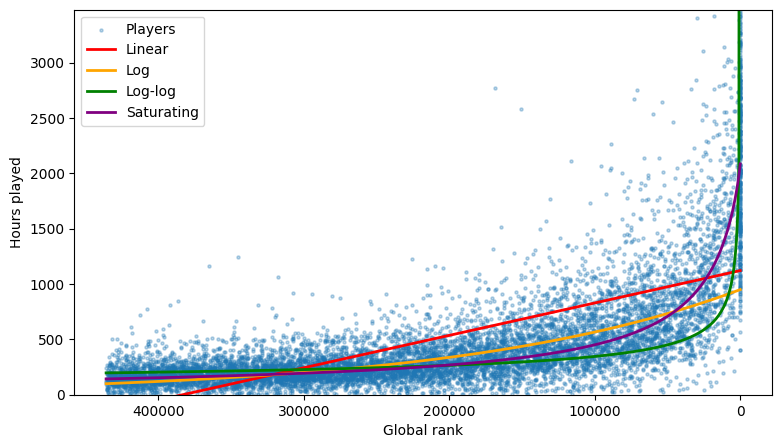

In [143]:
from scipy.optimize import curve_fit
from scipy import stats
import numpy as np

df = df[df.hours > 0]
x = df.global_rank.values
y = df.hours.values
# print(len(df), x.min(), x.max())

lin = stats.linregress(x, y)
log = stats.linregress(x, np.log(y))
pl  = stats.linregress(np.log(x), np.log(y))

p0 = [np.log(3000), np.log(5000), 0.5]
popt, _ = curve_fit(sat_log, np.log(x), np.log(y), p0=p0, maxfev=20000)
r0, k = np.exp(popt[0]), np.exp(popt[1]), popt[2]
def sat_log(lr, logH, logr0, k):
    # log(hours) = log(H) - log(1 + (rank/r0)^k), written in log-rank space
    return logH - np.log1p(np.exp(k * (lr - logr0)))
def pred_lin(r): return lin.intercept + lin.slope * r
def pred_log(r): return np.exp(log.intercept + log.slope * r)
def pred_pl(r):  return np.exp(pl.intercept + pl.slope * np.log(r))
def pred_sat(r): return np.exp(sat_log(np.log(r), *popt))   # NEW

# def r2(yhat):   return 1 - np.sum((y - yhat)**2) / np.sum((y - y.mean())**2)
# def rmse(yhat): return np.sqrt(np.mean((y - yhat)**2))
# print(f"Linear:    R²={r2(pred_lin(x)):.3f}  RMSE={rmse(pred_lin(x)):.0f} h")
# print(f"Log:       R²={r2(pred_log(x)):.3f}  RMSE={rmse(pred_log(x)):.0f} h")
# print(f"Log-log:   R²={r2(pred_pl(x)):.3f}  RMSE={rmse(pred_pl(x)):.0f} h  (exponent {pl.slope:.3f})")

xs = np.linspace(x.min(), x.max(), 500)
plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=5, alpha=0.3, label="Players")
plt.plot(xs, pred_lin(xs), color="red", lw=2, label="Linear")
plt.plot(xs, pred_log(xs), color="orange", lw=2, label="Log")
plt.plot(xs, pred_pl(xs), color="green", lw=2, label="Log-log")
plt.plot(xs, pred_sat(xs), color="purple", lw=2, label="Saturating")   # NEW
plt.xlabel("Global rank"); plt.ylabel("Hours played")
plt.ylim(0, np.percentile(y, 99) * 1.1)   # stops outliers squashing the plot
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [144]:
s = input("Input rank (blank to stop): ").strip()

r = int(s.replace(",", ""))
print(f"  Rank {r:,} → lin: {max(pred_lin(r), 0):.0f} | log: {pred_log(r):.0f} | log-log: {pred_pl(r):.0f} | saturating: {pred_sat(r):.0f} h")

Input rank (blank to stop): 92500
  Rank 92,500 → lin: 850 | log: 588 | log-log: 356 | saturating: 476 h


#For 5 digits

In [147]:
import requests, time
import pandas as pd
import matplotlib.pyplot as plt

START, END = 5, 45
total = END - START + 1
rows = []

def progress(done, total, width=30):
    filled = int(width * done / total)
    bar = "█" * filled + "-" * (width - filled)
    print(f"\r[{bar}] {done}/{total} pages ({done/total:.0%}) | {len(rows)} players", end="", flush=True)

progress(0, total)
for i, page in enumerate(range(START, END + 1), start=1):
    url = "https://osu.ppy.sh/api/v2/rankings/osu/performance"
    params = {"country": "ID", "cursor[page]": page}
    r = requests.get(url, headers=H, params=params)
    if r.status_code == 429:
        time.sleep(10)
        r = requests.get(url, headers=H, params=params)
    r.raise_for_status()
    for s in r.json()["ranking"]:
        rows.append({
            "user_id": s["user"]["id"],
            "username": s["user"]["username"],
            "global_rank": s.get("global_rank"),
            "pp": s["pp"],
            "hours": s["play_time"] / 3600,
        })
    progress(i, total)
    time.sleep(1.1)
print("\nDone!")

[██████████████████████████████] 41/41 pages (100%) | 2050 players
Done!


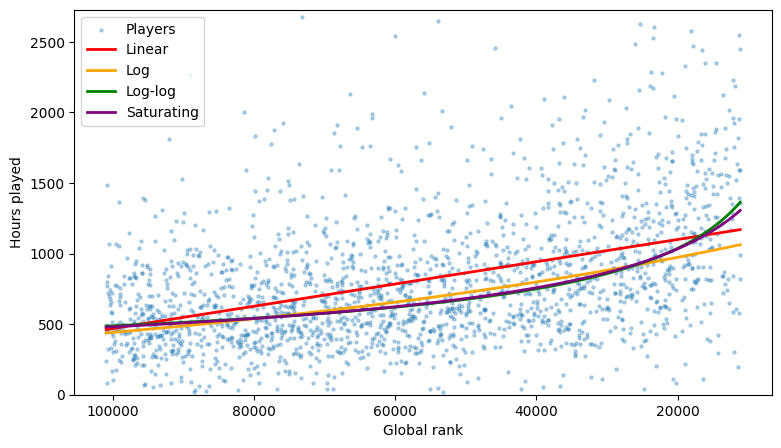

In [150]:
from scipy.optimize import curve_fit
from scipy import stats
import numpy as np
df = pd.DataFrame(rows)
df = df[df.hours > 0]
x = df.global_rank.values
y = df.hours.values
# print(len(df), x.min(), x.max())

lin = stats.linregress(x, y)
log = stats.linregress(x, np.log(y))
pl  = stats.linregress(np.log(x), np.log(y))

p0 = [np.log(3000), np.log(5000), 0.5]
popt, _ = curve_fit(sat_log, np.log(x), np.log(y), p0=p0, maxfev=20000)
H, r0, k = np.exp(popt[0]), np.exp(popt[1]), popt[2]
def sat_log(lr, logH, logr0, k):
    # log(hours) = log(H) - log(1 + (rank/r0)^k), written in log-rank space
    return logH - np.log1p(np.exp(k * (lr - logr0)))
def pred_lin(r): return lin.intercept + lin.slope * r
def pred_log(r): return np.exp(log.intercept + log.slope * r)
def pred_pl(r):  return np.exp(pl.intercept + pl.slope * np.log(r))
def pred_sat(r): return np.exp(sat_log(np.log(r), *popt))   # NEW

xs = np.linspace(x.min(), x.max(), 500)
plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=5, alpha=0.3, label="Players")
plt.plot(xs, pred_lin(xs), color="red", lw=2, label="Linear")
plt.plot(xs, pred_log(xs), color="orange", lw=2, label="Log")
plt.plot(xs, pred_pl(xs), color="green", lw=2, label="Log-log")
plt.plot(xs, pred_sat(xs), color="purple", lw=2, label="Saturating")   # NEW
plt.xlabel("Global rank"); plt.ylabel("Hours played")
plt.ylim(0, np.percentile(y, 99) * 1.1)   # stops outliers squashing the plot
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [151]:
s = input("Input rank (blank to stop): ").strip()

r = int(s.replace(",", ""))
print(f"  Rank {r:,} → lin: {max(pred_lin(r), 0):.0f} | log: {pred_log(r):.0f} | log-log: {pred_pl(r):.0f} | saturating: {pred_sat(r):.0f} h")

Input rank (blank to stop): 92500
  Rank 92,500 → lin: 528 | log: 475 | log-log: 506 | saturating: 501 h


#For 6 digits

In [154]:
import requests, time
import pandas as pd
import matplotlib.pyplot as plt

START, END = 45, 200
total = END - START + 1
rows = []

def progress(done, total, width=30):
    filled = int(width * done / total)
    bar = "█" * filled + "-" * (width - filled)
    print(f"\r[{bar}] {done}/{total} pages ({done/total:.0%}) | {len(rows)} players", end="", flush=True)

progress(0, total)
for i, page in enumerate(range(START, END + 1), start=1):
    url = "https://osu.ppy.sh/api/v2/rankings/osu/performance"
    params = {"country": "ID", "cursor[page]": page}
    r = requests.get(url, headers=H, params=params)
    if r.status_code == 429:
        time.sleep(10)
        r = requests.get(url, headers=H, params=params)
    r.raise_for_status()
    for s in r.json()["ranking"]:
        rows.append({
            "user_id": s["user"]["id"],
            "username": s["user"]["username"],
            "global_rank": s.get("global_rank"),
            "pp": s["pp"],
            "hours": s["play_time"] / 3600,
        })
    progress(i, total)
    time.sleep(1.1)
print("\nDone!")

[██████████████████████████████] 156/156 pages (100%) | 7800 players
Done!


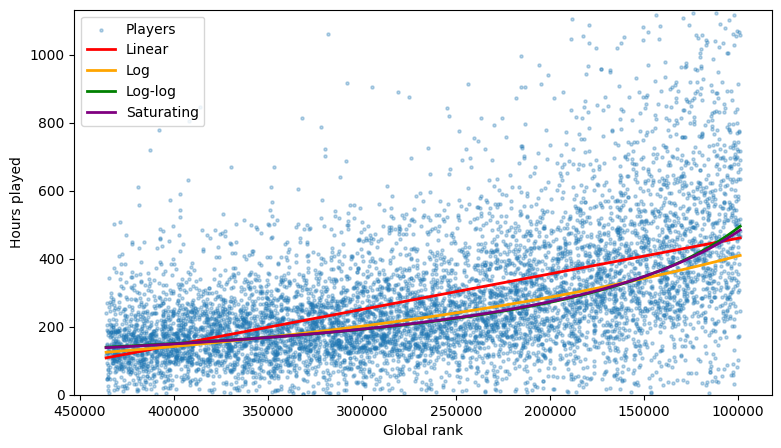

In [155]:
from scipy.optimize import curve_fit
from scipy import stats
import numpy as np
df = pd.DataFrame(rows)
df = df[df.hours > 0]
x = df.global_rank.values
y = df.hours.values
# print(len(df), x.min(), x.max())

lin = stats.linregress(x, y)
log = stats.linregress(x, np.log(y))
pl  = stats.linregress(np.log(x), np.log(y))

p0 = [np.log(3000), np.log(5000), 0.5]
popt, _ = curve_fit(sat_log, np.log(x), np.log(y), p0=p0, maxfev=20000)
H, r0, k = np.exp(popt[0]), np.exp(popt[1]), popt[2]
def sat_log(lr, logH, logr0, k):
    # log(hours) = log(H) - log(1 + (rank/r0)^k), written in log-rank space
    return logH - np.log1p(np.exp(k * (lr - logr0)))
def pred_lin(r): return lin.intercept + lin.slope * r
def pred_log(r): return np.exp(log.intercept + log.slope * r)
def pred_pl(r):  return np.exp(pl.intercept + pl.slope * np.log(r))
def pred_sat(r): return np.exp(sat_log(np.log(r), *popt))   # NEW

xs = np.linspace(x.min(), x.max(), 500)
plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=5, alpha=0.3, label="Players")
plt.plot(xs, pred_lin(xs), color="red", lw=2, label="Linear")
plt.plot(xs, pred_log(xs), color="orange", lw=2, label="Log")
plt.plot(xs, pred_pl(xs), color="green", lw=2, label="Log-log")
plt.plot(xs, pred_sat(xs), color="purple", lw=2, label="Saturating")   # NEW
plt.xlabel("Global rank"); plt.ylabel("Hours played")
plt.ylim(0, np.percentile(y, 99) * 1.1)   # stops outliers squashing the plot
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [158]:
s = input("Input rank (blank to stop): ").strip()

r = int(s.replace(",", ""))
print(f"  Rank {r:,} → lin: {max(pred_lin(r), 0):.0f} | log: {pred_log(r):.0f} | log-log: {pred_pl(r):.0f} | saturating: {pred_sat(r):.0f} h")

Input rank (blank to stop): 773,748
  Rank 773,748 → lin: 0 | log: 38 | log-log: 86 | saturating: 82 h
